<a href="https://colab.research.google.com/github/katekhayeayushramu/Agenti-ai/blob/main/week_11_%26_12_pynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATASET INFORMATION
Dataset shape: (178, 13)
Number of features: 13
Number of classes: 3

First five rows:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39

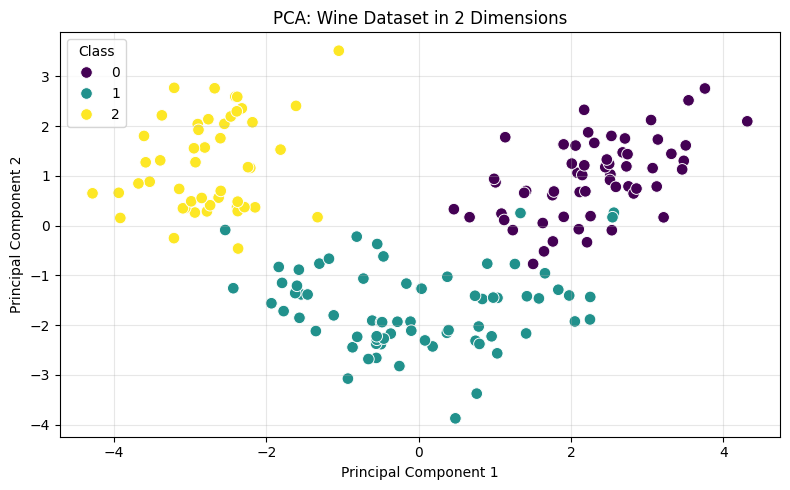


Cumulative explained variance:
[0.362 0.554 0.665 0.736 0.802 0.851 0.893 0.92  0.942 0.962 0.979 0.992
 1.   ]


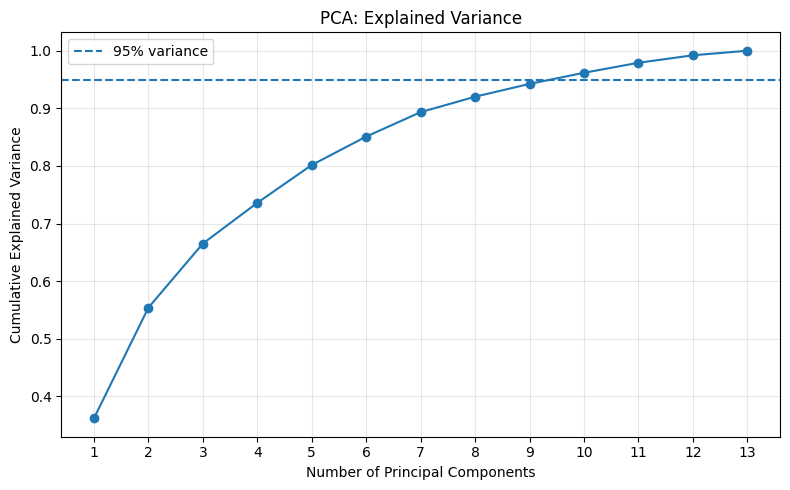


WEEK 12: t-SNE
t-SNE output shape: (178, 2)

First five t-SNE results:
   t-SNE Dimension 1  t-SNE Dimension 2  Class
0          10.311771          -8.546624      0
1           8.054532          -5.551340      0
2          12.126210          -3.887138      0
3          12.968869          -6.844522      0
4           9.538611          -0.349233      0


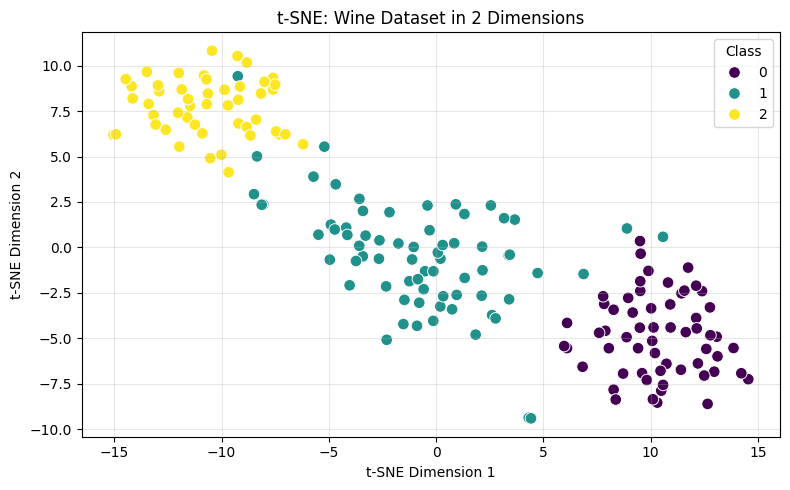

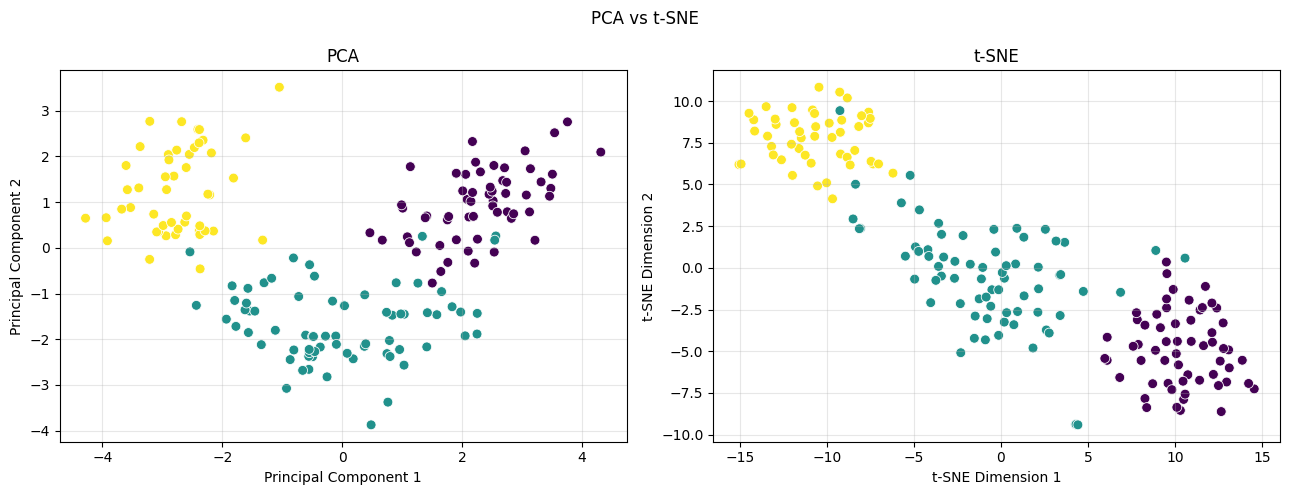


FINAL SUMMARY
PCA:
- Linear dimensionality reduction
- Finds directions that preserve maximum variance
- Explained variance can be measured
- Useful for compression and visualization

t-SNE:
- Nonlinear dimensionality reduction
- Tries to preserve nearby points in low dimensions
- Useful for visualizing clusters
- Distances between separate clusters may be misleading

Conclusion:
Both techniques reduce dimensions, but they optimize
different objectives. Neither is a predictive model.

Week 11 and Week 12 completed successfully!


In [ ]:

# ============================================================
# WEEK 11 & 12: DIMENSIONALITY REDUCTION
# PCA (Principal Component Analysis) + t-SNE
# Run the complete code in ONE Google Colab cell
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# ------------------------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------------------------

wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Number of classes:", len(np.unique(y)))
print("\nFirst five rows:")
print(X.head())

# ------------------------------------------------------------
# 2. DATA PREPROCESSING: FEATURE SCALING
# ------------------------------------------------------------

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\n" + "=" * 60)
print("DATA PREPROCESSING")
print("=" * 60)

print("Original shape:", X.shape)
print("Scaled data shape:", X_scaled.shape)
print("Mean of first 5 scaled features:",
      np.round(X_scaled.mean(axis=0)[:5], 3))

# ------------------------------------------------------------
# 3. WEEK 11: PCA
# Reduce 13 features to 2 principal components
# ------------------------------------------------------------

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("\n" + "=" * 60)
print("WEEK 11: PRINCIPAL COMPONENT ANALYSIS (PCA)")
print("=" * 60)

print("PCA output shape:", X_pca.shape)

print("\nExplained variance ratio:")
print(np.round(pca.explained_variance_ratio_, 4))

total_variance = pca.explained_variance_ratio_.sum()

print(f"\nTotal variance retained: {total_variance:.2%}")

# Display PCA results
pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal Component 1", "Principal Component 2"]
)
pca_df["Class"] = y

print("\nFirst five PCA results:")
print(pca_df.head())

# PCA visualization
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=pca_df,
    x="Principal Component 1",
    y="Principal Component 2",
    hue="Class",
    palette="viridis",
    s=70
)
plt.title("PCA: Wine Dataset in 2 Dimensions")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. PCA: EXPLAINED VARIANCE FOR ALL COMPONENTS
# ------------------------------------------------------------

pca_all = PCA()
pca_all.fit(X_scaled)

cumulative_variance = np.cumsum(
    pca_all.explained_variance_ratio_
)

print("\nCumulative explained variance:")
print(np.round(cumulative_variance, 3))

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)
plt.axhline(y=0.95, linestyle="--", label="95% variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA: Explained Variance")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. WEEK 12: t-SNE
# Nonlinear dimensionality reduction for visualization
# ------------------------------------------------------------

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    max_iter=1000,
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

print("\n" + "=" * 60)
print("WEEK 12: t-SNE")
print("=" * 60)

print("t-SNE output shape:", X_tsne.shape)

tsne_df = pd.DataFrame(
    X_tsne,
    columns=["t-SNE Dimension 1", "t-SNE Dimension 2"]
)
tsne_df["Class"] = y

print("\nFirst five t-SNE results:")
print(tsne_df.head())

# t-SNE visualization
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=tsne_df,
    x="t-SNE Dimension 1",
    y="t-SNE Dimension 2",
    hue="Class",
    palette="viridis",
    s=70
)
plt.title("t-SNE: Wine Dataset in 2 Dimensions")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. COMPARE PCA AND t-SNE
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=pca_df,
    x="Principal Component 1",
    y="Principal Component 2",
    hue="Class",
    palette="viridis",
    s=50,
    ax=axes[0],
    legend=False
)
axes[0].set_title("PCA")
axes[0].grid(alpha=0.3)

sns.scatterplot(
    data=tsne_df,
    x="t-SNE Dimension 1",
    y="t-SNE Dimension 2",
    hue="Class",
    palette="viridis",
    s=50,
    ax=axes[1],
    legend=False
)
axes[1].set_title("t-SNE")
axes[1].grid(alpha=0.3)

plt.suptitle("PCA vs t-SNE")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL SUMMARY")
print("=" * 60)

print("PCA:")
print("- Linear dimensionality reduction")
print("- Finds directions that preserve maximum variance")
print("- Explained variance can be measured")
print("- Useful for compression and visualization")

print("\nt-SNE:")
print("- Nonlinear dimensionality reduction")
print("- Tries to preserve nearby points in low dimensions")
print("- Useful for visualizing clusters")
print("- Distances between separate clusters may be misleading")

print("\nConclusion:")
print("Both techniques reduce dimensions, but they optimize")
print("different objectives. Neither is a predictive model.")
print("\nWeek 11 and Week 12 completed successfully!")
